In [1]:
from pathlib import Path

import colorcet as cc
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from dynamical_systems.analysis import lyapunov_gr
from dynamical_systems.continuous import Lorenz63, Lorenz96
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from dynamics_discovery.models import NeuralODE
from dynamics_discovery.utils.tree import tree_stack
from jaxtyping import Array, Float
from matplotlib_utils.plots import plot_line_and_band


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)


EXP_TYPES_ALL = (
    "vanilla",
    "neighborhood",
    "efficient_neighborhood",
    "dyslim",
    "dyslim_neigh",
)
EXP_TYPES = (
    "efficient_neighborhood",
    "vanilla",
    # "neighborhood",
    "dyslim",
    # "dyslim_neigh",
)

COLOR_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            cc.cm.glasbey_dark(45),
            cc.cm.glasbey_dark(0),
            cc.cm.glasbey_dark(64),
            cc.cm.glasbey_dark(46),
            cc.cm.glasbey_dark(91),
        ),
    )
)
LABEL_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            "Vanilla",
            "Neighborhood (Ours)",
            "Neighborhood (Ours)",
            "DySLIM (ICML 2024)",
            "DySLIM - Neighborhood",
        ),
    )
)

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

ODE_LABEL_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6D)",
    "lorenz96_18d": "Lorenz96 (18D)",
    "lorenz96_54d": "Lorenz96 (54D)",
}

In [2]:
def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_test_dataset(dataset_name: str, rootdir=Path("../../data/take3")):
    standardizer = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_train.hdf5"
    ).standardize()[1]
    dataset_test = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_test.hdf5"
    ).apply_transform(standardizer)
    return dataset_test, standardizer

In [3]:
LYAPUNOV_TIMES = {
    "lorenz63": (0.0, 400.0, 0.2),
    "lorenz96_6d": (0.0, 1500, 1.0),
    "lorenz96_18d": (0.0, 1500, 1.0),
    "lorenz96_54d": (0.0, 1500.0, 1.0),
}


def calculate_lyapunovs(
    dataset_name: str,
    exp_types=("efficient_neighborhood", "vanilla", "dyslim"),
    noises=(0.01, 0.05, 0.1),
    keys=(0, 10, 20),
):
    dataset_test, _ = load_test_dataset(dataset_name)

    @eqx.filter_jit
    @eqx.filter_vmap
    def calculate_lyapunov(model) -> Float[Array, " dim"]:
        lyas = eqx.filter_vmap(
            lambda u0_: lyapunov_gr(
                model,
                u0_,
                jnp.arange(*LYAPUNOV_TIMES[dataset_name]),
                rtol=1e-6,
                atol=1e-8,
                max_steps=2048,
            )[0][-1],
        )(dataset_test.u[:, 0])
        return jnp.mean(lyas, axis=0)

    models = {
        e: {n: [load_experiment(dataset_name, e, k, n) for k in keys] for n in noises}
        for e in exp_types
    }
    models_list, treedef = jax.tree.flatten(
        models, is_leaf=lambda x: isinstance(x, eqx.Module)
    )
    models_stacked = tree_stack(models_list)
    lyas: Float[Array, "models dim"] = calculate_lyapunov(models_stacked)

    return jax.tree.unflatten(treedef, lyas), dataset_test.metadata["lyapunovs"]

In [ ]:
lyas, lyas_true = calculate_lyapunovs("lorenz63", keys=(0,), noises=(0.01, 0.05, 0.1))

In [ ]:
lyas_true

array([ 2.12695061e+00,  1.64829700e+00,  1.23509599e+00,  8.45841658e-01,
        4.73286444e-01,  1.24125982e-01, -4.10544749e-04, -2.19403647e-01,
       -5.34560183e-01, -8.33879482e-01, -1.12488309e+00, -1.43551757e+00,
       -1.78825271e+00, -2.21523212e+00, -2.76296199e+00, -3.55837418e+00,
       -4.61911057e+00, -5.36101160e+00])

In [ ]:
lyas

{'dyslim': {0.01: [Array([ 2.15537252e+00,  1.67316474e+00,  1.25258701e+00,  8.57500524e-01,
           4.77581420e-01,  1.16296847e-01, -9.95382358e-04, -2.26906560e-01,
          -5.46554411e-01, -8.43237527e-01, -1.13856402e+00, -1.44763770e+00,
          -1.78898483e+00, -2.21689959e+00, -2.77801019e+00, -3.58159224e+00,
          -4.68101485e+00, -5.45225418e+00], dtype=float64)],
  0.05: [Array([ 2.11265909e+00,  1.63995785e+00,  1.22471871e+00,  8.25497048e-01,
           4.48997548e-01,  8.60058264e-02, -1.31982012e-03, -2.63163818e-01,
          -5.80512011e-01, -8.83277145e-01, -1.18044785e+00, -1.49235413e+00,
          -1.84363389e+00, -2.27134512e+00, -2.83357904e+00, -3.64163502e+00,
          -4.74400919e+00, -5.50074017e+00], dtype=float64)],
  0.1: [Array([ 1.95147865,  1.50627451,  1.10529291,  0.72285585,  0.3545048 ,
           0.01017943, -0.01860323, -0.3632482 , -0.6892446 , -0.99878572,
          -1.30030887, -1.60632506, -1.95469121, -2.37356286, -2.93477712,


In [ ]:
lya_nrmse = jax.tree.map(
    lambda x: {
        "mean": jnp.mean(jnp.asarray(x), axis=0),
        "std": jnp.std(jnp.asarray(x), axis=0),
    },
    jax.tree.map(lambda l: jnp.sqrt((l - lyas_true) ** 2) / jnp.abs(lyas_true), lyas),
    is_leaf=lambda x: isinstance(x, list),
)
lya_nrmse

{'dyslim': {0.01: {'mean': Array([1.33627527e-02, 1.50869306e-02, 1.41616702e-02, 1.37837451e-02,
          9.07479192e-03, 6.30741101e-02, 1.42454047e+00, 3.41968493e-02,
          2.24375644e-02, 1.12222990e-02, 1.21620915e-02, 8.44303837e-03,
          4.09402840e-04, 7.52729026e-04, 5.44640118e-03, 6.52490772e-03,
          1.34017744e-02, 1.70196562e-02], dtype=float64),
   'std': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.], dtype=float64)},
  0.05: {'mean': Array([0.00671925, 0.00505925, 0.008402  , 0.0240525 , 0.05131965,
          0.30710859, 2.2148021 , 0.19945052, 0.08596194, 0.05923837,
          0.04939602, 0.03959308, 0.03096943, 0.02533053, 0.02555846,
          0.02339856, 0.02703954, 0.02606384], dtype=float64),
   'std': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.], dtype=float64)},
  0.1: {'mean': Array([ 0.08249931,  0.08616317,  0.10509554,  0.14540051,  0.250972  ,
           0

In [ ]:
lya_smape = jax.tree.map(
    lambda x: {
        "mean": jnp.mean(jnp.asarray(x), axis=0),
        "std": jnp.std(jnp.asarray(x), axis=0),
    },
    jax.tree.map(
        lambda l: 2 * jnp.abs(l - lyas_true) / (jnp.abs(l) + jnp.abs(lyas_true)), lyas
    ),
    is_leaf=lambda x: isinstance(x, list),
)
lya_nrmse

{'dyslim': {0.01: {'mean': Array([1.33627527e-02, 1.50869306e-02, 1.41616702e-02, 1.37837451e-02,
          9.07479192e-03, 6.30741101e-02, 1.42454047e+00, 3.41968493e-02,
          2.24375644e-02, 1.12222990e-02, 1.21620915e-02, 8.44303837e-03,
          4.09402840e-04, 7.52729026e-04, 5.44640118e-03, 6.52490772e-03,
          1.34017744e-02, 1.70196562e-02], dtype=float64),
   'std': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.], dtype=float64)},
  0.05: {'mean': Array([0.00671925, 0.00505925, 0.008402  , 0.0240525 , 0.05131965,
          0.30710859, 2.2148021 , 0.19945052, 0.08596194, 0.05923837,
          0.04939602, 0.03959308, 0.03096943, 0.02533053, 0.02555846,
          0.02339856, 0.02703954, 0.02606384], dtype=float64),
   'std': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.], dtype=float64)},
  0.1: {'mean': Array([ 0.08249931,  0.08616317,  0.10509554,  0.14540051,  0.250972  ,
           0

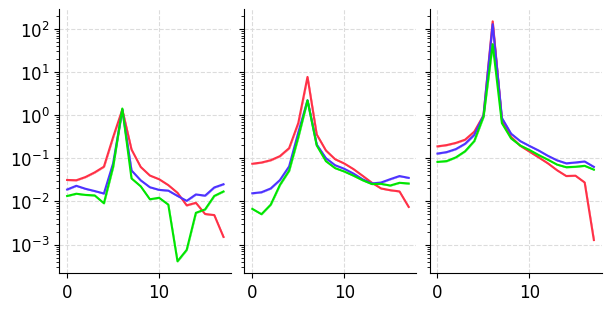

In [ ]:
noises = (0.01, 0.05, 0.1)
fig, axes = plt.subplots(1, 3, figsize=(6, 3), sharex=True, sharey=True)
for ax, n in zip(axes, noises):
    for exp_type in EXP_TYPES:
        plot_line_and_band(
            ax,
            np.arange(len(lya_nrmse[exp_type][n]["mean"])),
            lya_nrmse[exp_type][n]["mean"],
            lya_nrmse[exp_type][n]["std"],
            color=COLOR_DICT[exp_type],
        )
    ax.set_yscale("log")

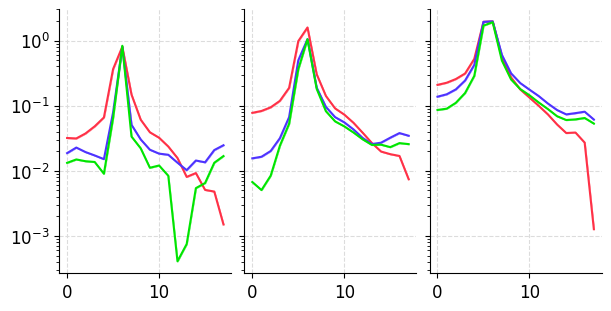

In [62]:
noises = (0.01, 0.05, 0.1)
fig, axes = plt.subplots(1, 3, figsize=(6, 3), sharex=True, sharey=True)
for ax, n in zip(axes, noises):
    for exp_type in EXP_TYPES:
        plot_line_and_band(
            ax,
            np.arange(len(lya_smape[exp_type][n]["mean"])),
            lya_smape[exp_type][n]["mean"],
            lya_smape[exp_type][n]["std"],
            color=COLOR_DICT[exp_type],
        )
    ax.set_yscale("log")